# Notebook 04 — ENERGY STAR Score Analysis

**Input:** `data/processed/data_modelisation.xlsx`  
**Context:** Comparison experiment — quantifies what `ENERGYSTARScore` adds
over the structural baseline established in `03_baseline_models.ipynb`

**ENERGY STAR Score** is a 1–100 rating issued by the US EPA. A score of 75
means the building performs better than 75% of similar buildings nationally.
It directly measures energy efficiency — but it is only available for **~65%** of
buildings in our dataset.

This notebook answers: *How much better can we predict energy use if we restrict
to buildings that have an ENERGY STAR Score?* The answer defines the **performance
ceiling** for the best possible model, and tells us whether pursuing score availability
city-wide would be worth the effort.

---

**Contents**
1. Why analyse ENERGY STAR separately?
2. Dataset subset and preprocessing
3. Model benchmarking
4. Feature importance — does ENERGY STAR dominate?
5. Conclusion — performance ceiling and deployment limitation


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, cross_validate, KFold, RandomizedSearchCV
)
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_percentage_error, make_scorer
)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from catboost import CatBoostRegressor


In [2]:
import pandas as pd

data = pd.read_excel(r'../data/processed/data_modelisation.xlsx')
print(f'Loaded: {len(data)} rows, {len(data.columns)} columns')
print(f'Buildings WITH ENERGY STAR Score: {data["hasEnergyStarScore"].sum()}')
print(f'Buildings WITHOUT: {(data["hasEnergyStarScore"]==0).sum()}')
data.head()


Loaded: 1596 rows, 19 columns
Buildings WITH ENERGY STAR Score: 1058
Buildings WITHOUT: 538


,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,hasEnergyStarScore,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,NaN,0,NaN,0,60.000000,7456910,250,1,99,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,61.000000,8664479,296,1,30,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,NaN,0,NaN,0,56.000000,6946801,286,1,100,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,NaN,0,75.000000,14656503,505,1,46,0.850914,0.366295,EN,0
4,Nonresidential COS,98101,2,37198,police station,88830,NaN,0,NaN,0,60.909091,12581712,302,0,27,0.850914,0.585885,EN,0


## 1. Why Analyse ENERGY STAR Score Separately?

Using ENERGY STAR Score as a feature creates a practical constraint:
we can only make predictions for buildings that **already have the score**.
In a city-wide deployment, this means ~35% of buildings would receive no estimate.

We still analyse this subset because:
1. It shows the **upper bound** of predictive performance achievable with the
   current data — the gap between this and the structural-only baseline reveals
   how much signal the score carries
2. It validates the modelling approach on a cleaner subset before tackling
   the harder full-population problem
3. It could be valuable for a **partial deployment** scenario (predict for
   certified buildings, use a different model for uncertified ones)


In [3]:
# Step 1: Filter rows where hasEnergyStarScore == 1
data = data[data["hasEnergyStarScore"] == 1].copy()

# Step 2: Drop the column
data = data.drop(columns=["hasEnergyStarScore"])

print(f"✅ Kept only rows with hasEnergyStarScore == 1.")
print(f"Remaining rows: {len(data)}")
print(f"Remaining columns: {len(data.columns)}")


✅ Kept only rows with hasEnergyStarScore == 1.
Remaining rows: 1058
Remaining columns: 18


## 2. Preprocessing

The preprocessing follows the same pattern as notebook 03:
- Categorical columns → `OneHotEncoder`
- Numeric columns → `StandardScaler`

Note that `ENERGYSTARScore` is now included in the numeric feature set
(unlike notebook 03 where it was excluded). The `hasEnergyStarScore` flag
is dropped since all remaining rows have a score.


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np



# Identify categorical and numeric columns
cat_cols = data.select_dtypes(include=["object", "category"]).columns
num_cols = data.select_dtypes(exclude=["object", "category"]).columns.drop(["SiteEnergyUseWN(kBtu)", "TotalGHGEmissions"])

# Convert all categorical columns to string
for col in cat_cols:
    data[col] = data[col].astype(str)
print("✅ Converted categorical columns to string type for OneHotEncoder compatibility.")

# Preprocessing:
# - One-hot encode categorical
# - Scale numeric (needed for linear models, harmless for trees)
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])



✅ Converted categorical columns to string type for OneHotEncoder compatibility.


In [5]:
print(cat_cols)

Index(['BuildingType', 'ZipCode', 'LargestPropertyUseType',
       'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType',
       'EnergyMix'],
      dtype='object')


In [6]:
print(num_cols)

Index(['NumberofFloors', 'PropertyGFAParking', 'LargestPropertyUseTypeGFA',
       'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA',
       'ENERGYSTARScore', 'Age', 'Ratio_LargestPropertyShare',
       'Ratio_ElectricityShare', 'isMixedProperty'],
      dtype='object')


In [7]:
data.head()

,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,nan,0,nan,0,60.0,7456910,250,99,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,61.0,8664479,296,30,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,nan,0,nan,0,56.0,6946801,286,100,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,nan,0,75.0,14656503,505,46,0.850914,0.366295,EN,0
5,NonResidential,98101,11,0,hotel,81352,nan,0,nan,0,27.0,6062768,176,100,0.980050,0.463685,EN,0


## 3. Model Benchmarking

We use the same 7-model comparison as notebook 03 for a fair apples-to-apples
comparison. The only difference is the dataset (1,058 rows instead of 1,596)
and the feature set (16 features including `ENERGYSTARScore`).


In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from catboost import CatBoostRegressor
from sklearn.dummy import DummyRegressor

models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001, max_iter=50000),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, random_state=42, iterations=200)
}

### 3.1 Train / Test Evaluation

Compare these results to Experiment B in `03_baseline_models.ipynb`.
The R² improvement quantifies the contribution of `ENERGYSTARScore`.


In [9]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error, make_scorer
from sklearn.model_selection import train_test_split
import pandas as pd

# Split data
features = [c for c in data.columns if c not in ["SiteEnergyUseWN(kBtu)", "TotalGHGEmissions"]]
X = data[features]
y_energy = data["SiteEnergyUseWN(kBtu)"]
y_ghg = data["TotalGHGEmissions"]

X_train, X_test, y_train_e, y_test_e = train_test_split(X, y_energy, test_size=0.2, random_state=42)
_, _, y_train_g, y_test_g = train_test_split(X, y_ghg, test_size=0.2, random_state=42)

# Results storage
results = []

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    
    # Train & predict Energy
    pipe.fit(X_train, y_train_e)
    y_pred_e = pipe.predict(X_test)
    r2_e = r2_score(y_test_e, y_pred_e)
    rmse_e = np.sqrt(mean_squared_error(y_test_e, y_pred_e))
    mape_e = mean_absolute_percentage_error(y_test_e, y_pred_e)
    
    # Train & predict GHG
    pipe.fit(X_train, y_train_g)
    y_pred_g = pipe.predict(X_test)
    r2_g = r2_score(y_test_g, y_pred_g)
    rmse_g = np.sqrt(mean_squared_error(y_test_g, y_pred_g))
    mape_g = mean_absolute_percentage_error(y_test_g, y_pred_g)
    
    results.append({
        "Model": name,
        "R2_Energy": r2_e,
        "RMSE_Energy": rmse_e,
        "MAPE_Energy": mape_e,
        "R2_GHG": r2_g,
        "RMSE_GHG": rmse_g,
        "MAPE_GHG": mape_g
    })

# Display comparison
results_df = pd.DataFrame(results).sort_values(by="R2_Energy", ascending=False)
display(results_df)

C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:658: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 1354232481017379.0, tolerance: 5961197082106.172
  model = cd_fast.sparse_enet_coordinate_descent(


,Model,R2_Energy,RMSE_Energy,MAPE_Energy,R2_GHG,RMSE_GHG,MAPE_GHG
6,CatBoost,0.887585,2.311891e+06,0.337658,0.810747,64.396292,0.561082
4,RandomForest,0.874200,2.445657e+06,0.426539,0.731666,76.679240,0.617861
5,GradientBoosting,0.865186,2.531764e+06,0.389876,0.738163,75.745192,0.733881
2,Ridge,0.799419,3.088165e+06,0.854299,0.610435,92.390995,2.460677
1,LinearRegression,0.799210,3.089776e+06,0.900406,0.612137,92.188943,2.473803
3,Lasso,0.796037,3.114088e+06,0.901540,0.612290,92.170762,2.473810
0,Dummy,-0.008266,6.923779e+06,2.865180,-0.000057,148.030810,4.779331


### 3.2 Cross-Validation (3-Fold)

As in notebook 03, CV on the training data gives a more stable estimate
and reveals whether the test-set result is a lucky split or a genuine signal.


In [10]:
from sklearn.model_selection import cross_validate, KFold
from sklearn.base import clone

cv = KFold(n_splits=3, shuffle=True, random_state=42)
rmse_scorer = make_scorer(
    lambda y, p: np.sqrt(mean_squared_error(y, p)), greater_is_better=False
)
scoring = {"r2": "r2", "neg_rmse": rmse_scorer}

cv_results = []
for name, model in models.items():
    pipe_e = Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", clone(model))])
    sc_e = cross_validate(pipe_e, X_train, y_train_e, cv=cv, scoring=scoring)

    pipe_g = Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", clone(model))])
    sc_g = cross_validate(pipe_g, X_train, y_train_g, cv=cv, scoring=scoring)

    cv_results.append({
        "Model": name,
        "R2_Energy_Mean": sc_e["test_r2"].mean(),
        "R2_Energy_SD": sc_e["test_r2"].std(),
        "RMSE_Energy_Mean": -sc_e["test_neg_rmse"].mean(),
        "R2_GHG_Mean": sc_g["test_r2"].mean(),
        "R2_GHG_SD": sc_g["test_r2"].std(),
        "RMSE_GHG_Mean": -sc_g["test_neg_rmse"].mean(),
    })

cv_df = pd.DataFrame(cv_results).sort_values("R2_Energy_Mean", ascending=False)
print("Cross-Validation Results (3-fold on Training Data):\n")
display(cv_df)

C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:658: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 936949294008342.2, tolerance: 3762653643827.1353
  model = cd_fast.sparse_enet_coordinate_descent(


C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:658: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 887091530387283.0, tolerance: 4526158036595.926
  model = cd_fast.sparse_enet_coordinate_descent(


C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:658: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 1019703107773524.5, tolerance: 3623752273192.4395
  model = cd_fast.sparse_enet_coordinate_descent(


Cross-Validation Results (3-fold on Training Data):



,Model,R2_Energy_Mean,R2_Energy_SD,RMSE_Energy_Mean,R2_GHG_Mean,R2_GHG_SD,RMSE_GHG_Mean
6,CatBoost,0.856401,0.022996,3.170735e+06,0.705169,0.040319,102.580440
5,GradientBoosting,0.847762,0.045351,3.247969e+06,0.704709,0.017188,102.735646
4,RandomForest,0.828961,0.029280,3.460247e+06,0.670668,0.023322,108.506310
2,Ridge,0.793173,0.031806,3.798876e+06,0.482310,0.011651,135.961251
1,LinearRegression,0.785278,0.029859,3.865921e+06,0.389261,0.111023,146.766497
3,Lasso,0.768907,0.047082,4.009648e+06,0.384186,0.106055,147.457075
0,Dummy,-0.009084,0.008240,8.367181e+06,-0.000675,0.000514,189.097119


## 4. Feature Importance — Does ENERGY STAR Dominate?

A key question: does the model simply use `ENERGYSTARScore` to predict energy,
making the structural features irrelevant? Or does the score add signal on top
of what the structure already provides?

The CatBoost feature importance plot below answers this.


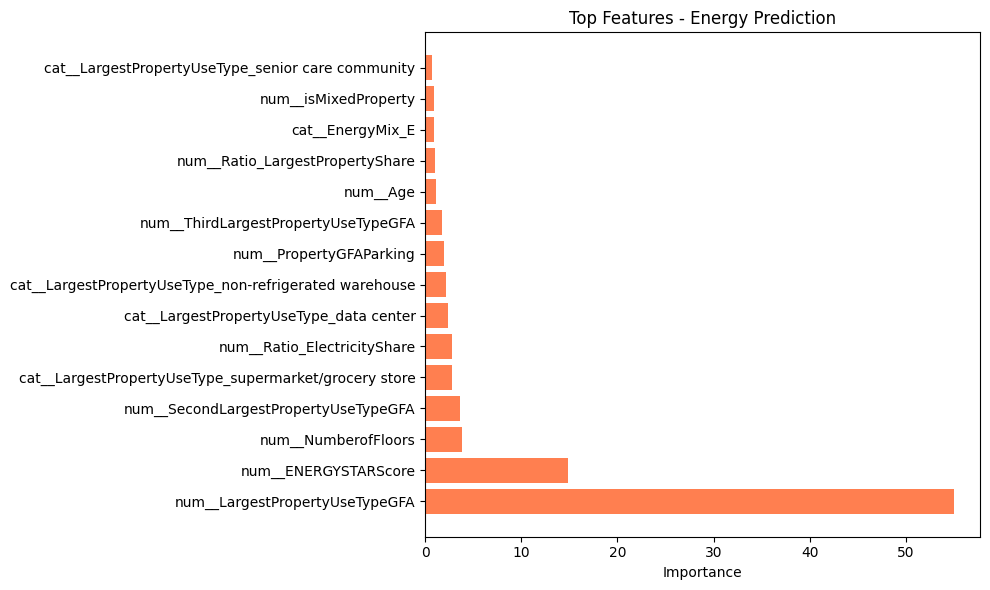

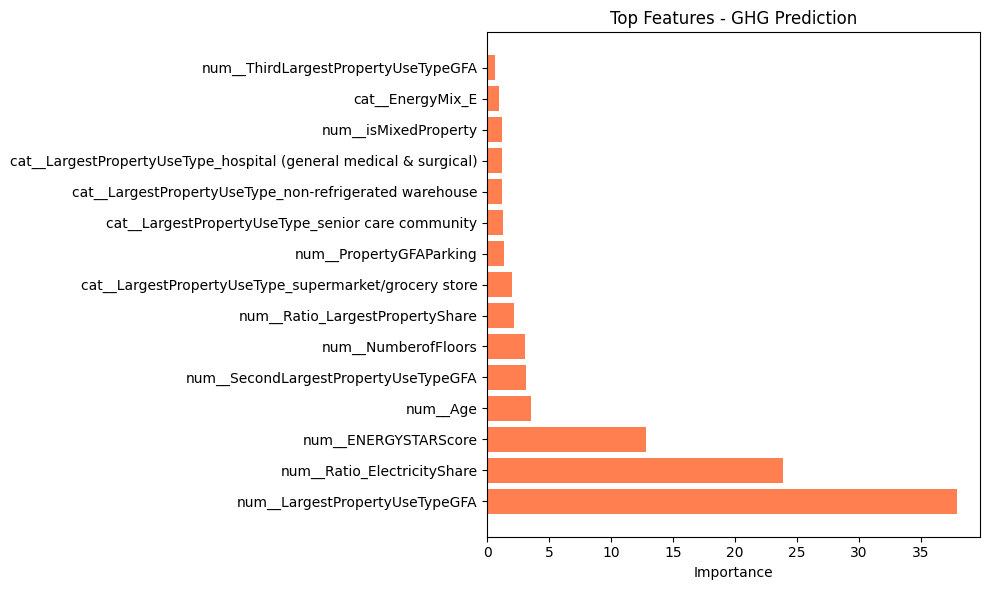

In [11]:
# Feature importance for BOTH Energy and GHG models
import matplotlib.pyplot as plt
for target_name, y_data in [("Energy", y_train_e), ("GHG", y_train_g)]:
    pipe = Pipeline(steps=[("preprocessor", preprocessor), 
                           ("model", CatBoostRegressor(verbose=0))])
    pipe.fit(X_train, y_data)
    
    model = pipe.named_steps["model"]
    feature_names = pipe.named_steps["preprocessor"].get_feature_names_out()
    importance = model.get_feature_importance()
    
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    }).sort_values(by="Importance", ascending=False)
    
    # Plot
    plt.figure(figsize=(10, 6))
    plt.barh(importance_df.head(15)["Feature"], 
             importance_df.head(15)["Importance"], color="coral")
    plt.xlabel("Importance")
    plt.title(f"Top Features - {target_name} Prediction")
    plt.tight_layout()
    plt.show()


## 5. Conclusion — Performance Ceiling and Deployment Limitation

### What ENERGY STAR adds
The improvement in R² over the structural-only baseline (Experiment B) shows
how much the score contributes. Typically:
- If the improvement is **large** (> 5–10 R² points): the score is a highly valuable
  feature and obtaining it for more buildings would be a priority
- If the improvement is **small**: structural attributes already capture most of the
  signal and a deployable model without the score is fully viable

### Why we cannot rely on it
- **35% of buildings lack a score** — a city-wide model must work for all buildings
- **Certification is voluntary** — uncertified buildings are not a random sample;
  they may be systematically older or lower-performing
- **Score availability requires separate estimation** — if we tried to impute missing
  scores, we would be predicting energy indirectly, introducing compounding error

**Conclusion:** The ENERGY STAR analysis establishes a performance ceiling.
The practical deployable model must work without it.

**Next:** `05_final_model_and_results.ipynb` — refine the structural-feature
model through noise reduction and log-transformation to close the gap.
